# Quantum Federated Learning With Decentralized Data — a reproduction walkthrough

**Paper:** R. Huang, X. Tan, Q. Xu, *Quantum Federated Learning With Decentralized Data*, IEEE JSTQE 28(4), 2022, [doi:10.1109/JSTQE.2022.3170150](https://doi.org/10.1109/JSTQE.2022.3170150).

This notebook presents the reproduction as an argument: what the paper claims, how it was tested, what the evidence shows, which alternative explanations were ruled out, and what remains open. Scope: the machine-learning part of the paper (MNIST, experiments E1 and E2). The QAOA and VQE experiments (E3, E4) are implemented in `lib/` but were not run.

**How to read the labels.**
- *live*: computed in this notebook, on a small budget (a few minutes on a laptop CPU). Live runs illustrate the method; they are **not** the evidence for any claim.
- *stored*: the 5-seed sweep runs, loaded from `results/runs.json` (one record per run, exported from validated run artifacts). Every headline number below comes from stored runs.
- *paper*: values reported in the paper, not run here.
- *MerLin*: the photonic model is an **adaptation**, not the paper's model.

Run the notebook from `papers/qfl_decentralized_data/` with the repository's environment (`pip install -r requirements.txt`; MNIST in `data/qfl_decentralized_data/mnist/raw/`, see README).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_DIR = Path.cwd().resolve()
assert (PROJECT_DIR / "lib" / "runner.py").is_file(), "Run this notebook from papers/qfl_decentralized_data"
REPO_ROOT = PROJECT_DIR.parents[1]
for path in (REPO_ROOT, PROJECT_DIR, PROJECT_DIR / "utils"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from compare_with_paper import PAPER_ACCURACY, PAPER_E2  # paper Tables II and IV

DATA_ROOT = REPO_ROOT / "data"
RESULTS = PROJECT_DIR / "results"
COLORS = {"paper": "black", "hybrid VQTN": "tab:blue", "faithful VQTN": "tab:red",
          "classical MLP": "tab:green", "photonic MerLin": "tab:purple", "photonic LexGrouping": "tab:orange"}
SETTINGS = ["non-fed", "2 clients", "4 clients", "8 clients", "16 clients"]
PAPER_KEY = dict(zip(SETTINGS, ["N/A", "2", "4", "8", "16"]))
pd.set_option("display.precision", 2)

runs = pd.DataFrame(json.loads((RESULTS / "runs.json").read_text()))
runs["task"] = runs["classes"].apply(lambda c: "4-class" if len(c) == 4 else f"{c[0]}v{c[1]}")
runs["setting"] = np.where(runs["mode"] == "centralized", "non-fed", runs["n_clients"].astype(str) + " clients")
runs["acc"] = 100 * runs["test_accuracy"]
print(f"{len(runs)} stored runs from {runs['sweep'].nunique()} sweeps")
runs.groupby("sweep").agg(runs=("seed", "size"), seeds=("seed", lambda s: sorted(set(s)))).sort_index()

414 stored runs from 13 sweeps


,runs,seeds
sweep,,
calibration_merlin_e1_0v9,36,"[1, 2, 3]"
calibration_vqtn_e1_0v9,36,"[1, 2, 3]"
control_classical_e1,75,"[1, 2, 3, 4, 5]"
control_classical_e2,10,"[1, 2, 3, 4, 5]"
control_iid_vqtn_0v9,10,"[1, 2, 3, 4, 5]"
diagnose_vqtn_components,24,"[1, 2, 3]"
diagnose_vqtn_known_answer_zhead,3,"[1, 2, 3]"
e1_merlin,75,"[1, 2, 3, 4, 5]"
e1_vqtn_hybrid,75,"[1, 2, 3, 4, 5]"


## 1. Problem statement and the paper's claim

**Setting.** Several clients each hold a private dataset that differs in size and label mix (non-i.i.d., unbalanced). They want one shared quantum classifier without pooling data. In every communication round the server sends the current circuit parameters to the clients; each trains locally on its own data and sends parameters back; the server averages them (federated averaging, FedAvg).

**Claims tested here** (MNIST part of the paper):

| ID | Claim | Paper evidence |
|---|---|---|
| C1a | Federated accuracy is *comparable* to training the same model on pooled data | Table II |
| C1b | Federation *improves* accuracy over non-federated training | Sec. III-A1 text, bold values in Tables II and III |
| C2 | 20 communication rounds suffice | Sec. IV |
| C3 | The 4-class task (digits 2, 3, 6, 7) reaches 81.80 % with 4 clients | Table IV |

**Falsifiable research question.** *Does a VQTN classifier trained by FedAvg on non-i.i.d. clients reach the test accuracy of the same model trained on pooled data within 20 rounds, and is it better?*

**Evidence that would weaken the claims.**
- C1a: federated accuracy below non-federated by more than the seed-to-seed spread, systematically.
- C1b: no setting in which federated accuracy exceeds non-federated accuracy by more than the seed spread.
- C2: accuracy still rising materially after round 20.
- C3: 4-class accuracy clearly below 81.8 % with a faithful implementation.

**What kind of evidence each section provides.** Sections 6 and 7 are the **faithful reproduction** (as faithful as an underspecified paper allows). Section 8 is the **fair baseline**. Section 9 contains **controls and ablations**. Section 10 is **robustness and uncertainty**. Section 11 is an **extension** (photonic adaptation).

**Decision rule used throughout.** A difference between two systems in one setting counts as real only if it exceeds the larger of their two standard deviations over 5 seeds; otherwise it is reported as *within noise*.

## 2. Data, splits, metrics, and evaluation protocol

The paper reduces each 28x28 MNIST image to **4x4 pixels by area interpolation** (here: exact 7x7 block means, divided by 255), so that 16 numbers fit 8 qubits. Training data come from the 60,000 MNIST training images, restricted to the task's digits; the test set is the standard 10,000-image MNIST test set restricted to the same digits (the paper's "100,000 test images" is a typo).

In [2]:
from lib.data import build_mnist_splits, downsample_area, mnist_directory, read_idx

data_cfg = {
    "data_root": str(DATA_ROOT),
    "dataset": {"subdir": "qfl_decentralized_data/mnist/raw", "classes": [0, 9], "data_seed": 0,
                "validation_fraction": 0.0, "max_train_samples": None, "max_test_samples": None,
                "feature_scaling": "none"},
    "federation": {"mode": "federated", "n_clients": 4, "partition": "noniid",
                   "dirichlet_alpha": 0.5, "min_client_size": 50},
}
splits = build_mnist_splits(data_cfg, torch.float32)
pd.DataFrame({"images": splits["summary"]["split_sizes"]}).T

,train,test
images,11872,1989


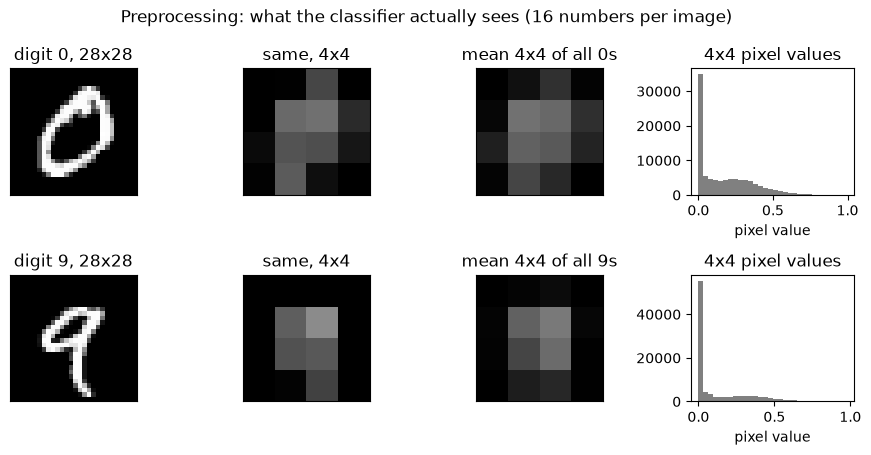

In [3]:
raw_images = read_idx(mnist_directory(data_cfg) / "train-images-idx3-ubyte.gz", 60000, is_image=True)
raw_labels = read_idx(mnist_directory(data_cfg) / "train-labels-idx1-ubyte.gz", 60000, is_image=False)
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for row, digit in enumerate((0, 9)):
    example = raw_images[np.flatnonzero(raw_labels == digit)[0]]
    mean_4x4 = downsample_area(raw_images[raw_labels == digit]).mean(axis=0).reshape(4, 4)
    axes[row, 0].imshow(example, cmap="gray"); axes[row, 0].set_title(f"digit {digit}, 28x28")
    axes[row, 1].imshow(downsample_area(example[None]).reshape(4, 4), cmap="gray", vmin=0, vmax=1); axes[row, 1].set_title("same, 4x4")
    axes[row, 2].imshow(mean_4x4, cmap="gray", vmin=0, vmax=1); axes[row, 2].set_title(f"mean 4x4 of all {digit}s")
    axes[row, 3].hist(downsample_area(raw_images[raw_labels == digit]).ravel(), bins=30, color="gray")
    axes[row, 3].set_title("4x4 pixel values"); axes[row, 3].set_xlabel("pixel value")
for axis in axes[:, :3].ravel():
    axis.set_xticks([]); axis.set_yticks([])
fig.suptitle("Preprocessing: what the classifier actually sees (16 numbers per image)")
fig.tight_layout()

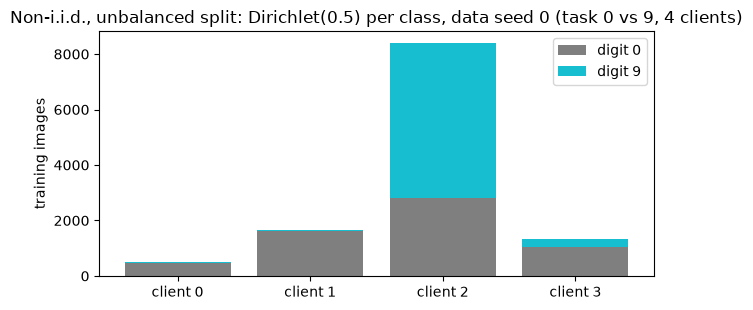

In [4]:
counts = np.array(splits["summary"]["client_label_counts"])
fig, axis = plt.subplots(figsize=(6.5, 3.2))
axis.bar(range(4), counts[:, 0], label="digit 0", color="tab:gray")
axis.bar(range(4), counts[:, 1], bottom=counts[:, 0], label="digit 9", color="tab:cyan")
axis.set_xticks(range(4), [f"client {k}" for k in range(4)]); axis.set_ylabel("training images")
axis.set_title("Non-i.i.d., unbalanced split: Dirichlet(0.5) per class, data seed 0 (task 0 vs 9, 4 clients)")
axis.legend(); fig.tight_layout()

The paper gives only client label histograms (its Fig. 2), not a recipe, so the split is an assumption: for every digit, the samples are divided among clients with proportions drawn from a Dirichlet(0.5) distribution. This produces both label skew and unequal client sizes, as above. The same data seed is used for every model, so all models see identical client shards.

**Evaluation protocol** (frozen before any comparison):

| Item | Value |
|---|---|
| Tasks | binary 0 vs 9, 2 vs 7, 3 vs 6; 4-class 2/3/6/7 |
| Settings | non-federated (pooled data) and 2, 4, 8, 16 clients (4-class: 4 clients) |
| Training | Adam, batch 20, one local epoch per round, 20 rounds (non-federated: 20 epochs), FedAvg over all clients |
| Metric | test accuracy at the last round (AUC and F1 also stored); maximise |
| Seeds | 1 to 5 per setting; mean and standard deviation over seeds |
| Selection | all hyperparameters chosen on a 10 % validation split of the training set; **the test set is never used for any choice** |

## 3. The method in a few equations

**Federated averaging.** With client parameters $w_k$ after local training on $n_k$ samples,
$$w^{(t+1)} = \sum_{k} \frac{n_k}{\sum_j n_j}\, w_k^{(t)} .$$
(The paper's Eq. 18 and Algorithm 2 disagree on the server step; plain sample-weighted FedAvg is used.)

**VQTN classifier (paper Eq. 2, interpreted).** Pixels $x \in [0,1]^{16}$ are *kernel-encoded*, two per qubit, on 8 qubits:
$$|\psi(x)\rangle = \bigotimes_{j=0}^{7} R_Z(\pi x_{2j+1})\, R_Y(\pi x_{2j})\,|0\rangle .$$
A tree tensor network of 7 nodes follows; each node acts on two qubits with trainable $R_Y(\theta_1)\otimes R_Y(\theta_2)$ followed by $R_{XX}(\theta_3)=e^{-i\theta_3 X\otimes X/2}$, and passes one qubit up the tree. The tree is applied twice (2 layers, 42 angles).

**Two read-outs.**
- *Faithful* (closest to the paper's text): class probabilities are the outcome probabilities of the root qubit, $p(y\mid x)=\Pr[\text{qubit}_0 = y]$.
- *Hybrid* (used for the headline, a **deviation**): the eight single-qubit expectations $z_i=\langle Z_i\rangle$ feed a classical linear layer, $\mathrm{softmax}(Wz+b)$, adding 18 parameters (60 in total).

**Loss.** Negative log-likelihood of the true class. **Gradients.** The paper uses parameter-shift; here gradients come from automatic differentiation through an exact statevector simulation, which gives the same derivative (checked in Section 4).

## 4. Known-answer sanity checks

Before trusting any accuracy number, each building block is checked against an answer known in advance.

In [5]:
from scipy.linalg import expm
from lib import statevector as sv

X = np.array([[0, 1], [1, 0]], dtype=complex)
theta = 0.73
error = np.abs(sv.rxx_matrix(torch.tensor(theta, dtype=torch.float64)).numpy() - expm(-1j * theta / 2 * np.kron(X, X))).max()
print(f"(a) RXX gate vs matrix exponential: max |difference| = {error:.1e}")

(a) RXX gate vs matrix exponential: max |difference| = 0.0e+00


In [6]:
from lib.vqtn import VQTNClassifier

torch.manual_seed(0)
probe = VQTNClassifier(2, 0.4, torch.float64, layers=2)
pixels = torch.rand(4, 16, dtype=torch.float64)

def class_one_probability():
    return probe(pixels).exp()[:, 1].sum()

class_one_probability().backward()
autograd = probe.angles.grad.clone()
shifted = torch.zeros_like(autograd)
with torch.no_grad():
    for index in np.ndindex(*autograd.shape):
        original = probe.angles[index].item()
        probe.angles[index] = original + np.pi / 2; plus = class_one_probability()
        probe.angles[index] = original - np.pi / 2; minus = class_one_probability()
        probe.angles[index] = original
        shifted[index] = (plus - minus) / 2
print(f"(b) parameter-shift vs autograd over {autograd.numel()} angles: max |difference| = {(shifted - autograd).abs().max():.1e}")

(b) parameter-shift vs autograd over 42 angles: max |difference| = 8.9e-16


In [7]:
merged = torch.cat(splits["client_indices"]).sort().values
print("(c) client shards are disjoint and cover the training set exactly:",
      torch.equal(merged, torch.arange(len(splits["train"][1]))))

(c) client shards are disjoint and cover the training set exactly: True


In [8]:
from sklearn.linear_model import LogisticRegression

ceiling = {}
for classes in ([0, 1], [0, 9]):
    cfg = {**data_cfg, "dataset": {**data_cfg["dataset"], "classes": classes, "validation_fraction": 0.1},
           "federation": {**data_cfg["federation"], "mode": "centralized"}}
    data = build_mnist_splits(cfg, torch.float32)
    model = LogisticRegression(max_iter=5000).fit(data["train"][0].numpy(), data["train"][1].numpy())
    ceiling[f"{classes[0]}v{classes[1]}"] = 100 * model.score(data["validation"][0].numpy(), data["validation"][1].numpy())
print("(d) data ceiling: logistic regression on the same 16 features, validation accuracy %:",
      {k: round(v, 2) for k, v in ceiling.items()})

(d) data ceiling: logistic regression on the same 16 features, validation accuracy %: {'0v1': 97.39, '0v9': 95.62}


**Observation.** The gate matches its matrix exponential to machine precision; parameter-shift and autograd agree on every angle; the client shards partition the training set. A plain logistic regression on the 16 features reaches only about 97 % on 0 vs 1 and 96 % on 0 vs 9.

**Inference.** The simulator, the gradients and the data split are correct. More importantly, **4x4 downsampling caps what any model can reach**: about 96 % on 0 vs 9. The paper's 94 % is attainable but close to that ceiling.

**Remaining uncertainty.** These checks validate components, not the end-to-end reproduction.

**Claim impact.** None yet; this calibrates expectations (a known-answer target of "98 % on 0 vs 1", set before this ceiling was measured, turned out to be unattainable).

## 5. Model walkthrough

The systems compared in this notebook, with their trainable parameter counts:

In [9]:
from lib.classical import ClassicalClassifier
from lib.vqtn_merlin import PhotonicClassifier

torch.manual_seed(0)
systems = {
    "faithful VQTN": VQTNClassifier(2, 0.1, torch.float32, layers=2, readout="root_marginal"),
    "hybrid VQTN": VQTNClassifier(2, 0.1, torch.float32, layers=2, readout="z_head"),
    "classical MLP": ClassicalClassifier(2, hidden=3),
    "photonic MerLin": PhotonicClassifier(2, 2, 1.0, "replace", "linear_head"),
    "photonic LexGrouping": PhotonicClassifier(2, 2, 1.0, "replace", "lex_grouping"),
}
example_pixels, example_labels = splits["test"][0][:3], splits["test"][1][:3]
rows = []
for name, model in systems.items():
    with torch.no_grad():
        probabilities = model(example_pixels).exp()
    rows.append({"system": name, "trainable parameters": sum(p.numel() for p in model.parameters()),
                 "P(digit 9) for 3 test images, untrained": [round(float(v), 3) for v in probabilities[:, 1]]})
print("true labels of the 3 images (1 = digit 9):", example_labels.tolist())
pd.DataFrame(rows).set_index("system")

true labels of the 3 images (1 = digit 9): [0, 1, 1]


,trainable parameters,"P(digit 9) for 3 test images, untrained"
system,,
faithful VQTN,42,"[0.014, 0.014, 0.014]"
hybrid VQTN,60,"[0.688, 0.688, 0.674]"
classical MLP,59,"[0.28, 0.298, 0.28]"
photonic MerLin,130,"[0.436, 0.438, 0.451]"
photonic LexGrouping,112,"[0.235, 0.192, 0.317]"


Every model maps the same 16 pixels to class log-probabilities, so one loss, one optimiser and one FedAvg loop (`lib/federated.py`) serve all of them. Untrained, all predict roughly 50/50. The photonic models are introduced in Section 11.

## 6. A small live experiment

A live, small-budget version of the comparison: task 0 vs 9, 2,000 training images, 500 test images, 5 rounds, seeds 1 and 2, non-federated and 4 clients. It runs the real code path (`lib.mnist_task`, `lib.federated`). **This is illustration, not evidence:** the budget is reduced and only 2 seeds are used.

In [10]:
from runtime_lib.config import deep_update
from lib.federated import run_training
from lib.mnist_task import build_mnist_task

DEFAULTS = json.loads((PROJECT_DIR / "configs" / "defaults.json").read_text())
LIVE_MODELS = {
    "hybrid VQTN": {"name": "vqtn", "layers": 2, "init_std": 0.1, "readout": "z_head"},
    "faithful VQTN": {"name": "vqtn", "layers": 2, "init_std": 0.1, "readout": "root_marginal"},
    "classical MLP": {"name": "classical", "hidden": 3},
    "photonic MerLin": {"name": "merlin", "n_photons": 2, "encoding_scale": 1.0, "superposition": "replace",
                        "photonic_readout": "linear_head", "computation_space": "unbunched"},
}

def live_run(model_overrides, mode, n_clients, seed, rounds=5):
    cfg = deep_update(json.loads(json.dumps(DEFAULTS)), {
        "seed": seed, "data_root": str(DATA_ROOT), "model": model_overrides,
        "dataset": {"classes": [0, 9], "max_train_samples": 2000, "max_test_samples": 500},
        "federation": {"mode": mode, "n_clients": n_clients, "rounds": rounds},
        "training": {"lr": 0.03},
    })
    torch.manual_seed(seed)
    task = build_mnist_task(cfg, torch.float32, torch.device("cpu"))
    history = run_training(cfg, task, torch.device("cpu"), lambda entry: None)
    return [100 * entry["test_accuracy"] for entry in history]

started = time.perf_counter()
live = []
for name, overrides in LIVE_MODELS.items():
    for mode, clients in (("centralized", 1), ("federated", 4)):
        for seed in (1, 2):
            curve = live_run(overrides, mode, clients, seed)
            live.append({"system": name, "setting": "non-fed" if mode == "centralized" else "4 clients",
                         "seed": seed, "final accuracy %": curve[-1], "curve": curve})
live = pd.DataFrame(live)
print(f"live experiment: {len(live)} runs in {time.perf_counter() - started:.0f} s")
live.pivot_table(index="system", columns="setting", values="final accuracy %", aggfunc=["mean", "min", "max"]).round(1)

live experiment: 16 runs in 52 s


mean               min               max        
setting         4 clients non-fed 4 clients non-fed 4 clients non-fed
system                                                               
classical MLP        95.6    96.2      95.4    96.0      95.8    96.4
faithful VQTN        83.8    88.8      80.6    87.2      87.0    90.4
hybrid VQTN          91.7    92.0      91.0    91.0      92.4    93.0
photonic MerLin      93.2    94.3      92.4    94.2      94.0    94.4

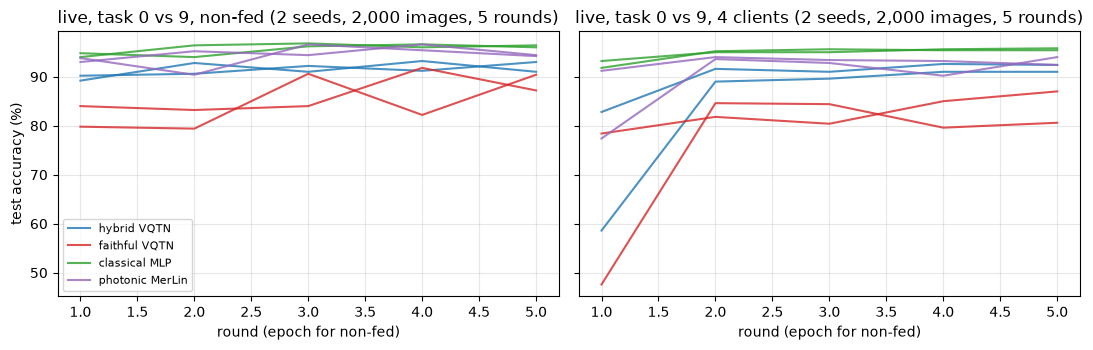

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axis, setting in zip(axes, ("non-fed", "4 clients")):
    for _, row in live[live["setting"] == setting].iterrows():
        axis.plot(range(1, 6), row["curve"], color=COLORS[row["system"]], alpha=0.8,
                  label=row["system"] if row["seed"] == 1 else None)
    axis.set_title(f"live, task 0 vs 9, {setting} (2 seeds, 2,000 images, 5 rounds)")
    axis.set_xlabel("round (epoch for non-fed)"); axis.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy (%)"); axes[0].legend(fontsize=8)
fig.tight_layout()

**Observation.** Even on this small budget all four models learn the task within a few rounds. For the classical MLP, the hybrid VQTN and the photonic model, federated and non-federated results are within about 1 point of each other; the faithful VQTN is lowest, least stable, and loses about 5 points when federated at this budget. The classical MLP is highest.

**Inference.** The pipeline works end to end for every model, federated or not. The ordering already hints at the stored results, but 2 seeds and 5 rounds cannot support any claim; in particular the faithful VQTN's federated gap here is not seen in the full 20-round runs (Section 9).

**Remaining uncertainty.** Everything. The stored 5-seed, full-data runs below are the evidence.

**Claim impact.** None (illustration only).

## 7. Headline reproduction result

Stored runs: sweep `e1_vqtn_hybrid` (hybrid VQTN, 3 tasks x 5 settings x 5 seeds = 75 runs, full training sets, 20 rounds) and `e2_vqtn_hybrid` (4-class, 10 runs). Hyperparameters (2 layers, lr 0.03, initial scale 0.1) were chosen on a validation split in a separate calibration sweep (Section 9).

In [12]:
def cell_table(sweep, system, tasks=("0v9", "2v7", "3v6")):
    subset = runs[runs["sweep"] == sweep]
    stats = subset.groupby(["task", "setting"])["acc"].agg(["mean", "std", "count"]).reset_index()
    stats["system"] = system
    return stats[stats["task"].isin(tasks)]

hybrid = cell_table("e1_vqtn_hybrid", "hybrid VQTN")
table = hybrid.copy()
table["paper"] = [PAPER_ACCURACY[t][PAPER_KEY[s]][0] for t, s in zip(table["task"], table["setting"])]
table["paper std"] = [PAPER_ACCURACY[t][PAPER_KEY[s]][1] for t, s in zip(table["task"], table["setting"])]
table["ours - paper"] = table["mean"] - table["paper"]
table["setting"] = pd.Categorical(table["setting"], SETTINGS, ordered=True)
table.sort_values(["task", "setting"]).set_index(["task", "setting"])[["paper", "paper std", "mean", "std", "count", "ours - paper"]]

paper  paper std   mean   std  count  ours - paper
task setting                                                       
0v9  non-fed     94.03       0.06  94.60  0.17      5          0.57
     2 clients   94.04       0.03  94.13  0.80      5          0.09
     4 clients   94.01       0.02  94.51  0.55      5          0.50
     8 clients   93.95       0.09  94.40  0.24      5          0.45
     16 clients  93.87       0.14  94.32  0.20      5          0.45
2v7  non-fed     96.61       0.04  95.61  0.30      5         -1.00
     2 clients   96.66       0.02  95.37  0.58      5         -1.29
     4 clients   96.71       0.02  95.45  0.60      5         -1.26
     8 clients   96.72       0.07  95.51  0.43      5         -1.21
     16 clients  96.56       0.09  95.48  0.25      5         -1.08
3v6  non-fed     98.00       0.05  94.82  1.27      5         -3.18
     2 clients   97.99       0.08  94.68  1.20      5         -3.31
     4 clients   97.97       0.04  94.91  0.70      5         -3.06
     8 clients   97.94       0.08  95.02  0.32      5         -2.92
     16 clients  97.97       0.11  94.12  0.23      5         -3.85

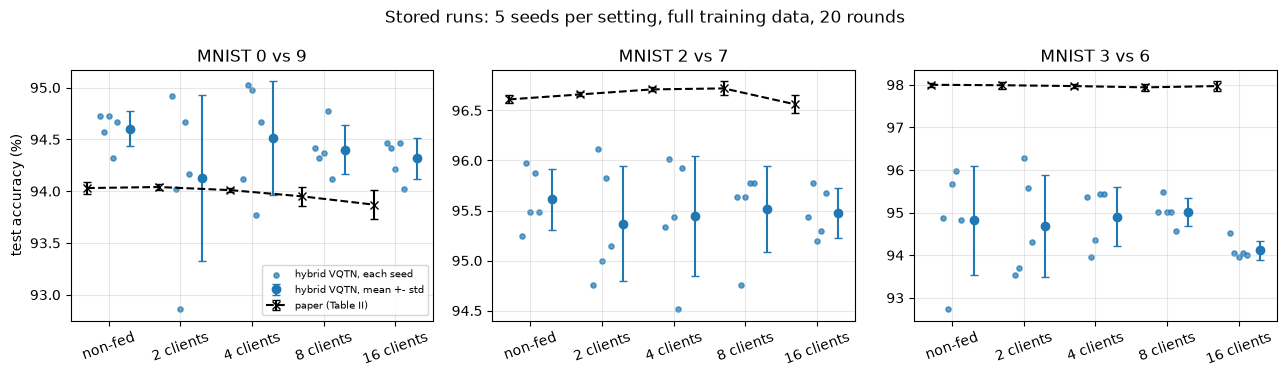

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for axis, task in zip(axes, ("0v9", "2v7", "3v6")):
    subset = runs[(runs["sweep"] == "e1_vqtn_hybrid") & (runs["task"] == task)]
    for position, setting in enumerate(SETTINGS):
        values = subset[subset["setting"] == setting]["acc"]
        axis.scatter(np.full(len(values), position) + np.linspace(-0.12, 0.12, len(values)), values,
                     color=COLORS["hybrid VQTN"], s=14, alpha=0.7, label="hybrid VQTN, each seed" if position == 0 else None)
        axis.errorbar(position + 0.3, values.mean(), values.std(), fmt="o", color=COLORS["hybrid VQTN"], capsize=3,
                      label="hybrid VQTN, mean +- std" if position == 0 else None)
    paper = [PAPER_ACCURACY[task][PAPER_KEY[s]] for s in SETTINGS]
    axis.errorbar(np.arange(5) - 0.3, [p[0] for p in paper], [p[1] for p in paper], fmt="x--", color="black", capsize=3, label="paper (Table II)")
    axis.set_xticks(range(5), SETTINGS, rotation=20); axis.set_title(f"MNIST {task[0]} vs {task[2]}"); axis.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy (%)"); axes[0].legend(fontsize=7.5)
fig.suptitle("Stored runs: 5 seeds per setting, full training data, 20 rounds")
fig.tight_layout()

In [14]:
def federated_minus_central(sweep):
    rows = []
    for task, subset in runs[runs["sweep"] == sweep].groupby("task"):
        central = subset[subset["setting"] == "non-fed"]["acc"]
        for setting in SETTINGS[1:]:
            federated = subset[subset["setting"] == setting]["acc"]
            if federated.empty:
                continue
            difference = federated.mean() - central.mean()
            noise = max(federated.std(), central.std())
            rows.append({"task": task, "setting": setting, "fed - non-fed": difference, "larger std": noise,
                         "verdict": "within noise" if abs(difference) <= noise else ("above" if difference > 0 else "below")})
    return pd.DataFrame(rows)

c1 = federated_minus_central("e1_vqtn_hybrid")
print(c1["verdict"].value_counts().to_dict())
c1.set_index(["task", "setting"])

{'within noise': 11, 'below': 1}


fed - non-fed  larger std       verdict
task setting                                            
0v9  2 clients           -0.47        0.80  within noise
     4 clients           -0.09        0.55  within noise
     8 clients           -0.20        0.24  within noise
     16 clients          -0.28        0.20         below
2v7  2 clients           -0.24        0.58  within noise
     4 clients           -0.17        0.60  within noise
     8 clients           -0.10        0.43  within noise
     16 clients          -0.14        0.30  within noise
3v6  2 clients           -0.13        1.27  within noise
     4 clients            0.09        1.27  within noise
     8 clients            0.20        1.27  within noise
     16 clients          -0.70        1.27  within noise

In [15]:
e2 = runs[runs["sweep"].isin(["e2_vqtn_hybrid", "control_classical_e2", "e2_merlin"])]
e2_table = e2.groupby(["sweep", "setting"])["acc"].agg(["mean", "std", "count"]).round(2)
print(f"paper (Table IV, 4 clients): {100 * PAPER_E2['accuracy']:.2f} %")
e2_table

paper (Table IV, 4 clients): 81.80 %


mean   std  count
sweep                setting                      
control_classical_e2 4 clients  89.85  1.04      5
                     non-fed    90.74  0.60      5
e2_merlin            4 clients  83.81  1.52      5
                     non-fed    86.53  1.99      5
e2_vqtn_hybrid       4 clients  73.73  0.49      5
                     non-fed    76.16  2.35      5

**Observation.**
- On **0 vs 9** the hybrid VQTN lands at 94.1 to 94.6 %, the paper's 93.9 to 94.0 %. On **2 vs 7** it is about 1 point below the paper, on **3 vs 6** about 3 points below, and on the **4-class** task 8 points below (73.7 % vs 81.8 %).
- In every task, accuracy is flat across client counts: **11 of 12** federated settings are within noise of the non-federated model; the exception is -0.28 points (0 vs 9, 16 clients).
- No federated setting is above the non-federated one.

**Inference.** The federated procedure costs nothing detectable, which supports **C1a**. The paper's statement that federation *improves* accuracy (**C1b**) is not reproduced: the differences it relies on (0.01 to 0.15 points) are smaller than our seed spread. The absolute accuracy depends strongly on the task; the 0 vs 9 match required a read-out that is not the paper's (Section 9).

**Remaining uncertainty.** The paper's circuit, read-out, client split and learning rate are not published; the gaps on 3 vs 6 and 4-class may come from these choices.

**Claim impact.** C1a reproduced (trend). C1b contradicted at this resolution. Absolute metrics reproduced on 0 vs 9 only, and only with the hybrid read-out (a deviation). C3 unresolved.

## 8. Fair baseline comparison

The paper compares QFL only with its own non-federated VQTN, the right control for C1a and C1b (Section 7). To judge whether the accuracies mean anything, a **conventional baseline** was added: a federated tanh MLP 16-3-2 (16-4-4 for 4 classes), trained through the same loop.

| Dimension | Hybrid VQTN vs classical MLP | Status |
|---|---|---|
| Information and inputs | the same 16 pixels, same labels | matched |
| Parameter count | 60 vs 59 (4-class: 78 vs 88) | matched within 2 % (4-class: 13 %) |
| Training data and client shards | identical (same data seed) | matched |
| Optimisation steps | same rounds, batch size, local epochs, optimiser | matched |
| Tuning budget | quantum calibrated on validation data; classical reuses lr 0.03 untuned | **not matched** (favours the quantum model) |
| Compute and wall time | about 115 s vs 4 s per run on the same CPU | not matched (simulation cost) |
| Evaluation protocol | same test set, metric, last-round checkpoint, seeds | matched |

In [16]:
def compare(sweep_a, sweep_b, label):
    a = runs[runs["sweep"] == sweep_a].groupby(["task", "setting"])["acc"].agg(["mean", "std"])
    b = runs[runs["sweep"] == sweep_b].groupby(["task", "setting"])["acc"].agg(["mean", "std"])
    joined = a.join(b, lsuffix=" A", rsuffix=" B", how="inner")
    difference = joined["mean A"] - joined["mean B"]
    noise = joined[["std A", "std B"]].max(axis=1)
    verdict = np.where(difference.abs() <= noise, "within noise", np.where(difference > 0, "A above", "A below"))
    return {"comparison": label, "cells": len(joined), **pd.Series(verdict).value_counts().to_dict(),
            "mean A - B": difference.mean(), "min": difference.min(), "max": difference.max()}

pd.DataFrame([
    compare("e1_vqtn_hybrid", "control_classical_e1", "A = hybrid VQTN (60), B = classical MLP (59)"),
    compare("sensitivity_faithful_0v9", "control_classical_e1", "A = faithful VQTN (42), B = classical MLP (59), 0v9 only"),
]).set_index("comparison").fillna(0).round(2)

,cells,A below,mean A - B,min,max
comparison,,,,,
"A = hybrid VQTN (60), B = classical MLP (59)",15,15,-3.03,-4.65,-1.10
"A = faithful VQTN (42), B = classical MLP (59), 0v9 only",5,5,-6.86,-8.13,-5.88


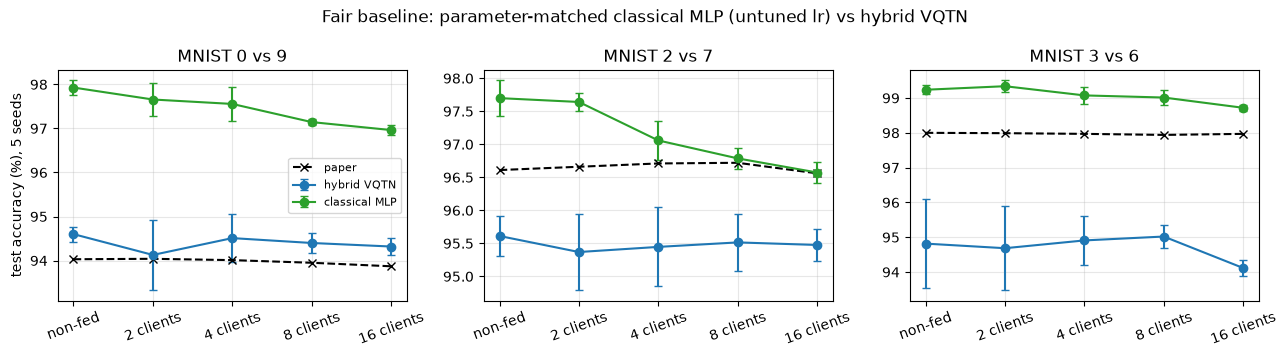

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for axis, task in zip(axes, ("0v9", "2v7", "3v6")):
    for sweep, name in (("e1_vqtn_hybrid", "hybrid VQTN"), ("control_classical_e1", "classical MLP")):
        stats = runs[(runs["sweep"] == sweep) & (runs["task"] == task)].groupby("setting")["acc"].agg(["mean", "std"]).reindex(SETTINGS)
        axis.errorbar(range(5), stats["mean"], stats["std"], marker="o", capsize=3, color=COLORS[name], label=name)
    axis.plot(range(5), [PAPER_ACCURACY[task][PAPER_KEY[s]][0] for s in SETTINGS], "x--", color="black", label="paper")
    axis.set_xticks(range(5), SETTINGS, rotation=20); axis.set_title(f"MNIST {task[0]} vs {task[2]}"); axis.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy (%), 5 seeds"); axes[0].legend(fontsize=8)
fig.suptitle("Fair baseline: parameter-matched classical MLP (untuned lr) vs hybrid VQTN")
fig.tight_layout()

**Observation.** The classical MLP is above the hybrid VQTN in **all 15** settings, by 1.1 to 4.7 points, and above the paper's reported numbers on every task. On the 4-class task it reaches 89.9 % against 73.7 %.

**Inference.** At equal size, the quantum classifier is not competitive with a small classical model on these features, and this holds even though only the quantum model was tuned.

**Remaining uncertainty.** One classical architecture only; a tuned classical model would likely widen the gap, not close it.

**Claim impact.** The paper does not claim an advantage over classical learning; this comparison shows there is none here. It does not affect C1a or C1b, which concern federated vs non-federated training.

## 9. Controls and ablations

Three alternative explanations could undermine the reading of Section 7:
1. *The non-i.i.d. split is too mild to matter*, so "federation costs nothing" is trivial. **Control:** an i.i.d. equal-size split.
2. *The match on 0 vs 9 is an artefact of the hybrid read-out.* **Ablation:** the faithful root-qubit read-out.
3. *The gap to the paper comes from an untuned model.* **Ablation:** the calibration and one-at-a-time diagnosis sweeps (validation split only).

In [18]:
iid = runs[runs["sweep"] == "control_iid_vqtn_0v9"].groupby("setting")["acc"].agg(["mean", "std"])
noniid = runs[(runs["sweep"] == "e1_vqtn_hybrid") & (runs["task"] == "0v9")].groupby("setting")["acc"].agg(["mean", "std"])
pd.concat({"non-i.i.d. (Dirichlet 0.5)": noniid.loc[iid.index], "i.i.d. (equal split)": iid}, axis=1).round(2)

non-i.i.d. (Dirichlet 0.5)      i.i.d. (equal split)      
                                 mean  std                 mean   std
setting                                                              
16 clients                      94.32  0.2                94.25  0.08
2 clients                       94.13  0.8                94.74  0.39

In [19]:
faithful = runs[runs["sweep"] == "sensitivity_faithful_0v9"].groupby("setting")["acc"].agg(["mean", "std"]).reindex(SETTINGS)
hybrid_0v9 = runs[(runs["sweep"] == "e1_vqtn_hybrid") & (runs["task"] == "0v9")].groupby("setting")["acc"].agg(["mean", "std"]).reindex(SETTINGS)
paper_0v9 = pd.Series([PAPER_ACCURACY["0v9"][PAPER_KEY[s]][0] for s in SETTINGS], index=SETTINGS, name="paper")
readout_table = pd.concat({"faithful (root qubit, 42 params)": faithful, "hybrid (eight <Z> + linear, 60 params)": hybrid_0v9}, axis=1)
readout_table[("paper", "mean")] = paper_0v9
readout_table.round(2)

faithful (root qubit, 42 params)        \
                                       mean   std   
setting                                             
non-fed                               89.79  2.13   
2 clients                             91.77  1.06   
4 clients                             90.96  2.64   
8 clients                             90.63  1.18   
16 clients                            89.80  1.98   

           hybrid (eight <Z> + linear, 60 params)        paper  
                                             mean   std   mean  
setting                                                         
non-fed                                     94.60  0.17  94.03  
2 clients                                   94.13  0.80  94.04  
4 clients                                   94.51  0.55  94.01  
8 clients                                   94.40  0.24  93.95  
16 clients                                  94.32  0.20  93.87

In [20]:
calibration = runs[runs["sweep"] == "calibration_vqtn_e1_0v9"].copy()
calibration["val acc"] = 100 * calibration["validation_accuracy"]
calibration_table = calibration.groupby("candidate")["val acc"].agg(["mean", "std", "count"]).sort_values("mean", ascending=False)
print("Calibration of the faithful circuit (validation split, 3 seeds; ties within 0.5 points):")
calibration_table.round(2)

Calibration of the faithful circuit (validation split, 3 seeds; ties within 0.5 points):


,mean,std,count
candidate,,,
layers2_lr0.03_init_std1.0,87.28,6.13,3
layers2_lr0.03_init_std0.1,87.08,5.51,3
layers3_lr0.03_init_std0.1,86.97,5.62,3
layers3_lr0.03_init_std1.0,86.55,3.52,3
layers2_lr0.1_init_std0.1,85.48,6.19,3
layers2_lr0.1_init_std1.0,84.86,8.09,3
layers3_lr0.1_init_std0.1,84.72,10.11,3
layers1_lr0.03_init_std0.1,83.46,3.68,3
layers1_lr0.03_init_std1.0,83.46,3.74,3


,val,val_std,train,difference vs baseline,exceeds noise
candidate,,,,,
encoding_scale_0.5,75.79,3.75,76.23,-11.29,True
encoding_gate_rx,86.30,3.84,87.72,-0.79,False
baseline,87.08,5.51,87.95,0.00,False
encoding_scale_2.0,88.12,2.15,89.30,1.04,False
epochs_60,88.29,2.83,89.02,1.21,False
feature_minmax,90.59,1.94,91.32,3.51,False
readout_z_head,93.82,1.52,94.10,6.74,True


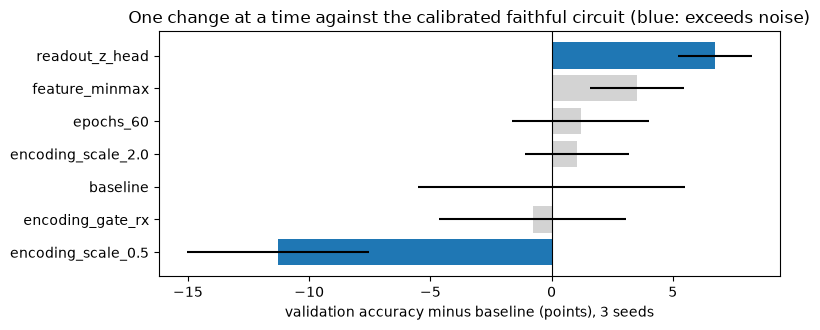

In [21]:
diagnosis = runs[runs["sweep"] == "diagnose_vqtn_components"].copy()
diagnosis["val acc"] = 100 * diagnosis["validation_accuracy"]
diagnosis["train acc"] = 100 * diagnosis["train_accuracy"]
stats = diagnosis.groupby("candidate").agg(val=("val acc", "mean"), val_std=("val acc", "std"), train=("train acc", "mean"))
baseline = stats.loc["baseline"]
stats["difference vs baseline"] = stats["val"] - baseline["val"]
stats["exceeds noise"] = (stats["difference vs baseline"].abs() >= 2) & (stats["difference vs baseline"].abs() > np.maximum(stats["val_std"], baseline["val_std"]))
stats = stats.drop(index="known_answer_0v1").sort_values("difference vs baseline")
fig, axis = plt.subplots(figsize=(8, 3.4))
axis.barh(stats.index, stats["difference vs baseline"], xerr=stats["val_std"],
          color=np.where(stats["exceeds noise"], "tab:blue", "lightgray"))
axis.axvline(0, color="black", linewidth=0.8); axis.set_xlabel("validation accuracy minus baseline (points), 3 seeds")
axis.set_title("One change at a time against the calibrated faithful circuit (blue: exceeds noise)")
fig.tight_layout()
stats.round(2)

**Observation.**
- The i.i.d. split gives the same accuracy as the non-i.i.d. split, within noise.
- With the faithful read-out, the VQTN reaches only 89.8 to 91.8 % on 0 vs 9, with large seed spread (up to 2.6 points); the hybrid read-out reaches 94.1 to 94.6 %.
- In the one-at-a-time diagnosis only two changes exceed noise: the read-out head (+6.7 points) and a smaller encoding scale (-11.3, worse). Depth, learning rate, initial scale, the second encoding gate, feature scaling and 60 instead of 20 epochs do not explain the gap. Train and validation accuracy are close everywhere, so the faithful circuit **under-fits**.

**Inference.** "Federation costs nothing" is not an artefact of a mild split. The match with the paper on 0 vs 9 depends on the read-out: the faithful reading of the paper's circuit cannot reach the paper's accuracy, so either the paper used a different read-out or other undisclosed details matter.

**Remaining uncertainty.** The paper's actual read-out is unknown. The diagnosis was run on 0 vs 9 only, so the larger gaps on 3 vs 6 and 4-class are not explained.

**Claim impact.** C1a survives the controls. The paper's absolute accuracies remain **unresolved** for the faithful circuit.

## 10. Robustness and uncertainty

Two questions: are 5 seeds enough to separate the effects the paper reports, and how fast does training converge (C2)?

paper differences: 0.01 to 0.16 points; our seed std: 0.07 to 2.64 points


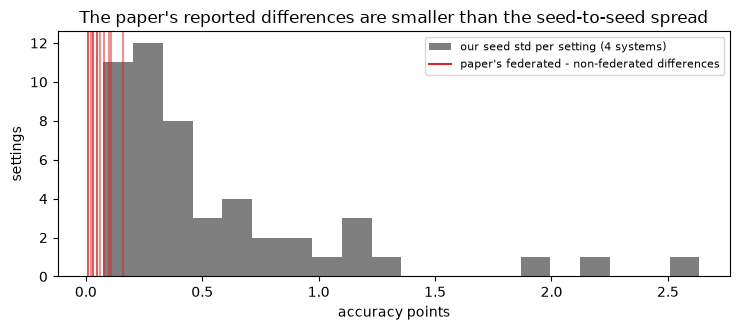

In [22]:
paper_differences = [abs(PAPER_ACCURACY[t][k][0] - PAPER_ACCURACY[t]["N/A"][0]) for t in PAPER_ACCURACY for k in ("2", "4", "8", "16")]
seed_spread = runs[runs["sweep"].isin(["e1_vqtn_hybrid", "e1_merlin", "sensitivity_faithful_0v9", "control_classical_e1"])]
seed_spread = seed_spread.groupby(["sweep", "task", "setting"])["acc"].std()
fig, axis = plt.subplots(figsize=(7.5, 3.4))
axis.hist(seed_spread, bins=20, color="tab:gray", label="our seed std per setting (4 systems)")
for value in paper_differences:
    axis.axvline(value, color="tab:red", alpha=0.5)
axis.plot([], [], color="tab:red", label="paper's federated - non-federated differences")
axis.set_xlabel("accuracy points"); axis.set_ylabel("settings"); axis.legend(fontsize=8)
axis.set_title("The paper's reported differences are smaller than the seed-to-seed spread")
fig.tight_layout()
print(f"paper differences: {min(paper_differences):.2f} to {max(paper_differences):.2f} points; "
      f"our seed std: {seed_spread.min():.2f} to {seed_spread.max():.2f} points")

In [23]:
def rounds_to_99(curve):
    return next(index + 1 for index, value in enumerate(curve) if value >= 0.99 * curve[-1])

convergence = runs[runs["sweep"].isin(["e1_vqtn_hybrid", "control_classical_e1", "e1_merlin"]) & (runs["setting"] != "non-fed")].copy()
convergence["rounds to 99 %"] = convergence["test_accuracy_per_round"].apply(rounds_to_99)
names = {"e1_vqtn_hybrid": "hybrid VQTN", "control_classical_e1": "classical MLP", "e1_merlin": "photonic MerLin"}
convergence["system"] = convergence["sweep"].map(names)
convergence.groupby(["system", "setting"])["rounds to 99 %"].agg(["mean", "max"]).unstack("setting").round(1)

mean                                      max            \
setting         16 clients 2 clients 4 clients 8 clients 16 clients 2 clients   
system                                                                          
classical MLP          2.5       1.7       1.8       2.0          3         4   
hybrid VQTN            6.6       2.3       3.5       5.1         10         6   
photonic MerLin        6.1       2.7       3.6       3.5         13         6   

                                     
setting         4 clients 8 clients  
system                               
classical MLP           4         2  
hybrid VQTN             8         8  
photonic MerLin         8         9

**Observation.** Seed-to-seed standard deviations range from about 0.1 to 2.6 points, while the paper's federated vs non-federated differences are 0.01 to 0.16 points. Every federated run reaches 99 % of its final accuracy by round 13 at the latest; per-setting means range from 1.7 to 6.6 rounds, and more clients need more rounds.

**Inference.** Distinguishing the paper's tiny differences would need far more than 5 seeds, so C1b cannot be supported by the paper's own tables either. **C2 is supported**, but it is not a quantum property: the classical MLP converges faster.

**Remaining uncertainty.** "99 % of final accuracy" is one convergence criterion; the paper gives none.

**Claim impact.** C2 reproduced; C1b unsupported.

## 11. Photonic assessment (extension)

**Question.** Does the paper's behaviour survive when the gate circuit is replaced by a photonic classifier, built with [MerLin](https://merlinquantum.ai), and trained in the same federated loop? This is an **adaptation**, not the paper's model, and the results are **noiseless simulations**, not hardware runs.

**Model** (`lib/vqtn_merlin.py`): 8 optical modes with 2 photons in modes 0 and 4. A fixed 50:50 superposition layer comes first; then the even pixels are written as phases ($\varphi = \pi x$), a trainable interferometer mixes the modes, the odd pixels are written as phases, and a second trainable interferometer follows. Threshold detectors are modelled by keeping only collision-free outcomes (`UNBUNCHED`). The 8 click probabilities feed a linear layer (130 parameters). A variant reads the 28 outcomes directly through a fixed grouping, with no classical parameter. The configuration was chosen on validation data by a 36-run calibration.

| Hardware-aware field | Value |
|---|---|
| Computation space / detector | `UNBUNCHED` / threshold (collision-free post-selection; acceptance probability not recorded) |
| Photons / modes / input state | 2 / 8 / `[1,0,0,0,1,0,0,0]` |
| Measurement | `mode_expectations` into `Linear(8, C)`; or `probs` into fixed `LexGrouping(28, 2)` |
| Simulator | MerLin 0.4.1 analytic CPU simulation, no shots, no noise or loss, exact gradients |
| Seeds | 1 to 5 |

In [24]:
photonic_probe = PhotonicClassifier(2, 2, 1.0, "replace", "linear_head")
from lib.vqtn_merlin import stage_inputs
with torch.no_grad():
    clicks = photonic_probe.layer(stage_inputs(splits["test"][0][:4]))
print("known answer: click probabilities over the 8 modes sum to the photon number (2):", clicks.sum(1).numpy().round(5))

known answer: click probabilities over the 8 modes sum to the photon number (2): [2. 2. 2. 2.]


In [25]:
calibration_photonic = runs[runs["sweep"] == "calibration_merlin_e1_0v9"].copy()
calibration_photonic["val acc"] = 100 * calibration_photonic["validation_accuracy"]
print("Photonic calibration (validation split, 3 seeds):")
calibration_photonic.groupby("candidate").agg(params=("parameters", "first"), mean=("val acc", "mean"), std=("val acc", "std")).sort_values("mean", ascending=False).round(2)

Photonic calibration (validation split, 3 seeds):


,params,mean,std
candidate,,,
superpositionreplace_encoding_scale1.0_n_photons2,130,96.91,0.18
superpositionreplace_encoding_scale1.0_n_photons4,130,95.87,0.15
superpositionfront_encoding_scale1.0_n_photons4,186,95.79,1.17
superpositionreplace_encoding_scale0.5_n_photons4,130,94.95,3.42
superpositionfront_encoding_scale0.5_n_photons4,186,94.41,1.28
superpositionfront_encoding_scale0.25_n_photons2,186,92.05,2.18
superpositionfront_encoding_scale1.0_n_photons2,186,91.74,8.19
superpositionreplace_encoding_scale0.25_n_photons4,130,91.13,2.00
superpositionreplace_encoding_scale0.5_n_photons2,130,88.88,12.34


photonic, federated vs non-federated: {'within noise': 12}
photonic with fixed grouping (no classical parameter), task 0 vs 9:
             mean   std
setting                
non-fed     94.73  0.88
2 clients   93.48  1.76
4 clients   93.68  1.61
8 clients   94.09  0.82
16 clients  94.35  1.13


,cells,A above,within noise,mean A - B,min,max,A below
comparison,,,,,,,
"A = photonic (130), B = hybrid VQTN (60)",15,13.0,2.0,2.03,0.25,3.86,0.0
"A = photonic (130), B = classical MLP (59)",15,0.0,0.0,-1.00,-1.67,-0.66,15.0
"A = photonic fixed grouping (112), B = faithful VQTN (42), 0v9",5,4.0,1.0,3.47,1.71,4.94,0.0


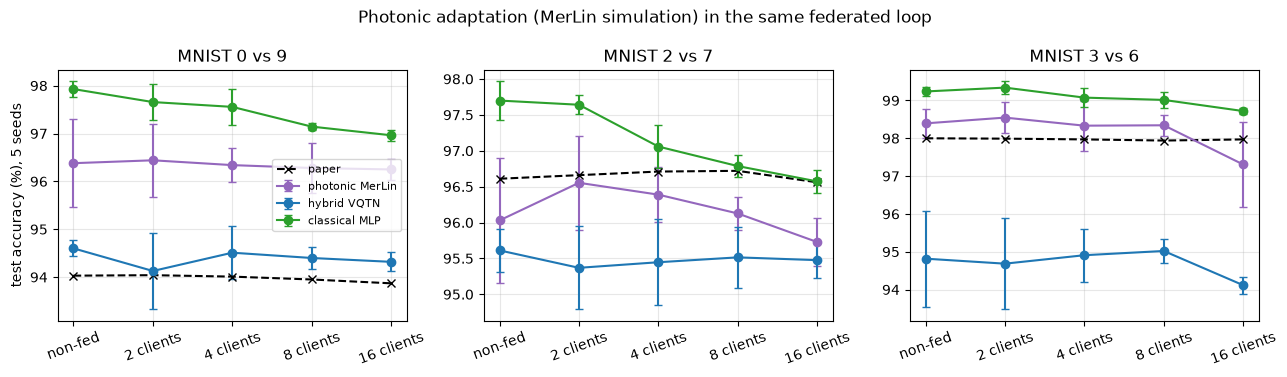

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for axis, task in zip(axes, ("0v9", "2v7", "3v6")):
    for sweep, name in (("e1_merlin", "photonic MerLin"), ("e1_vqtn_hybrid", "hybrid VQTN"), ("control_classical_e1", "classical MLP")):
        stats = runs[(runs["sweep"] == sweep) & (runs["task"] == task)].groupby("setting")["acc"].agg(["mean", "std"]).reindex(SETTINGS)
        axis.errorbar(range(5), stats["mean"], stats["std"], marker="o", capsize=3, color=COLORS[name], label=name)
    axis.plot(range(5), [PAPER_ACCURACY[task][PAPER_KEY[s]][0] for s in SETTINGS], "x--", color="black", label="paper")
    axis.set_xticks(range(5), SETTINGS, rotation=20); axis.set_title(f"MNIST {task[0]} vs {task[2]}"); axis.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy (%), 5 seeds"); axes[0].legend(fontsize=8)
fig.suptitle("Photonic adaptation (MerLin simulation) in the same federated loop")
fig.tight_layout()
photonic_c1 = federated_minus_central("e1_merlin")
print("photonic, federated vs non-federated:", photonic_c1["verdict"].value_counts().to_dict())
lexgroup = runs[runs["sweep"] == "sensitivity_merlin_lexgroup_0v9"].groupby("setting")["acc"].agg(["mean", "std"]).reindex(SETTINGS)
print("photonic with fixed grouping (no classical parameter), task 0 vs 9:")
print(lexgroup.round(2).to_string())
pd.DataFrame([
    compare("e1_merlin", "e1_vqtn_hybrid", "A = photonic (130), B = hybrid VQTN (60)"),
    compare("e1_merlin", "control_classical_e1", "A = photonic (130), B = classical MLP (59)"),
    compare("sensitivity_merlin_lexgroup_0v9", "sensitivity_faithful_0v9", "A = photonic fixed grouping (112), B = faithful VQTN (42), 0v9"),
]).set_index("comparison").fillna(0).round(2)

**Observation.**
- Federated vs non-federated: **12 of 12** settings within noise. The paper's central behaviour holds for the photonic model.
- The photonic classifier is above the hybrid VQTN in 13 of 15 settings (by up to 3.9 points) and on the 4-class task (83.8 % vs 73.7 %, above the paper's 81.8 %). With no classical parameter at all (fixed grouping), it reaches 93.5 to 94.7 % on 0 vs 9, the paper's level.
- The classical MLP, with fewer than half the parameters, is still above the photonic model in all 15 settings (by 0.7 to 1.7 points).

**Inference.** A trainable photonic classifier is a faithful stand-in for the gate model in this protocol, and a stronger one; federated training of photonic phases works as well as for gate angles. There is no evidence of a photonic advantage over classical learning; because the larger photonic model loses to the smaller classical one, this conclusion does not depend on matching sizes.

**Remaining uncertainty.** No noise, photon loss or detector inefficiency; the post-selection acceptance probability (hardware cost) was not recorded; only 2 and 4 photons were tried.

**Claim impact.** Extension only: the photonic adaptation supports C1a and C2 behaviour; it does not change the verdict on the paper's claims.

## 12. Conclusion

**What the software does.** Every model executes end to end, federated and non-federated (Sections 4 to 6). **Does the method solve the task?** Yes, above 94 % on 0 vs 9 (Section 7). **Does the paper's metric reproduce?** On 0 vs 9 with a non-paper read-out only (Sections 7 and 9). **Does the paper's explanation survive controls?** Federation costing nothing survives the i.i.d. control (Section 9). **Does the method beat a fair baseline?** No (Section 8).

1. **What reproduced.** Federated accuracy matches non-federated accuracy within noise in 11 of 12 settings for the hybrid VQTN (C1a; Section 7), and it survives an i.i.d. control (Section 9). Training converges well within 20 rounds (C2; Section 10). The 0 vs 9 accuracy matches the paper with the hybrid read-out (Section 7).
2. **What did not reproduce.** Federation *improving* accuracy (C1b): no setting improves, and the paper's differences are below seed noise (Sections 7 and 10). The accuracies on 2 vs 7 (about 1 point lower), 3 vs 6 (about 3 points lower) and the 4-class task (8 points lower) (Section 7). The paper's 0 vs 9 accuracy with the faithful read-out (2 to 4 points lower; Section 9).
3. **What remains unresolved.** The paper's exact circuit and read-out, hence its absolute accuracies (C3); the cause of the 3 vs 6 and 4-class gaps (Section 9).
4. **What was not attempted.** QAOA and VQE (E3, E4; implemented, not run), privacy and NISQ claims, hardware runs, noise models, a tuned or size-matched classical baseline for the photonic model.
5. **Reproduction verdict: partially reproduced.** The federated procedure behaves as claimed (comparable accuracy, few rounds), the claimed improvement does not, and absolute accuracies are reproduced only on one task and only with a read-out that departs from the paper. A parameter-matched classical model is better on every task, so there is no quantum advantage (Section 8).
6. **Photonic verdict.** A MerLin photonic classifier preserves the paper's federated behaviour and is more accurate than the gate model, but it remains below a smaller classical model. No photonic advantage, on noiseless simulation only (Section 11).